In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from msuthemes import theme_msu, colors
from scipy.signal import find_peaks
from moviepy.editor import VideoFileClip
import warnings
warnings.simplefilter("ignore")
FS= 20
GSR_LAG = 4.5

In [29]:
tc_df_manipulated = pd.read_csv("/Users/schmaelz/Documents/01_GITHUB/nomcomm/GITHUB_PAPERS_WORKING/PC_HJ/data/04_analysis/reversecorrelation_manipulated/GSR_split_timecourse.csv")
tc_df_manipulated['Average'] = (tc_df_manipulated['Group_1'] + tc_df_manipulated['Group_2']) / 2
window_size = int(FS * 1.0) # 1 second smoothing
tc_df_manipulated['Smooth_GSR'] = tc_df_manipulated['Average'].rolling(window=window_size, center=True).mean().fillna(tc_df_manipulated['Average'])

MIN_HEIGHT    = 1.    # Minimum amplitude (in Z-score units, usually >0.5 or >1.0)
MIN_DIST_SEC  = 5   # Minimum seconds between peaks (to avoid double-counting one event)
PROMINENCE    = 1.5    # How much the peak stands out from the surrounding baseline

peaks_indices_manipulated, properties = find_peaks(
    tc_df_manipulated['Smooth_GSR'], 
    height=MIN_HEIGHT, 
    distance=MIN_DIST_SEC * FS,
    prominence=PROMINENCE
)

print(f"Found {len(peaks_indices_manipulated)} peaks in the group physiological signal.")

Found 15 peaks in the group physiological signal.


In [30]:
tc_df = pd.read_csv("/Users/schmaelz/Documents/01_GITHUB/nomcomm/GITHUB_PAPERS_WORKING/PC_HJ/data/04_analysis/h1_results/all_subjects/GSR_split_timecourse.csv")
tc_df['Average'] = (tc_df['Group_1'] + tc_df['Group_2']) / 2
window_size = int(FS * 1.0) # 1 second smoothing
tc_df['Smooth_GSR'] = tc_df['Average'].rolling(window=window_size, center=True).mean().fillna(tc_df['Average'])

MIN_HEIGHT    = 1.8    # Minimum amplitude (in Z-score units, usually >0.5 or >1.0)
MIN_DIST_SEC  = 10   # Minimum seconds between peaks (to avoid double-counting one event)
PROMINENCE    = 2.5    # How much the peak stands out from the surrounding baseline

peaks_indices, properties = find_peaks(
    tc_df['Smooth_GSR'], 
    height=MIN_HEIGHT, 
    distance=MIN_DIST_SEC * FS,
    prominence=PROMINENCE
)

print(f"Found {len(peaks_indices)} peaks in the group physiological signal.")

Found 8 peaks in the group physiological signal.


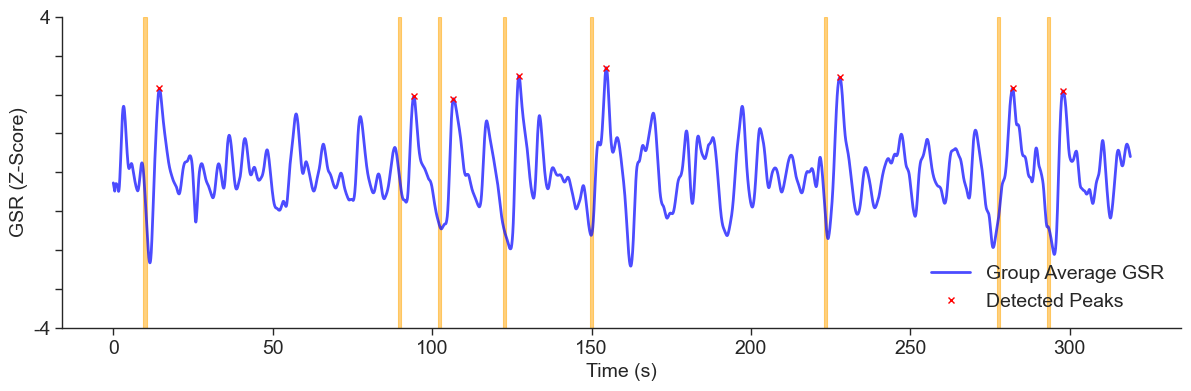

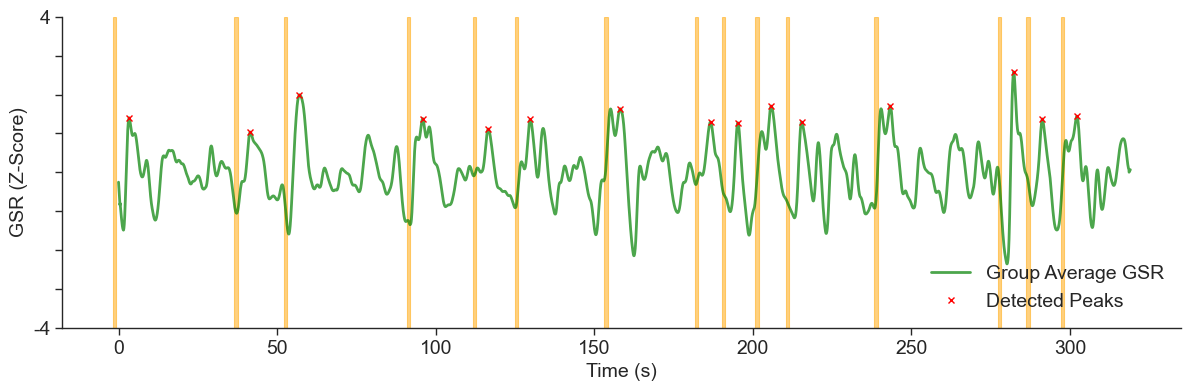

In [31]:
# ==========================================
# VISUALIZATION (Sanity Check)
# ==========================================
sns.set_theme(font='Arial')

sns.set(style="ticks", context="paper")

plt.figure(figsize=(12, 4))
plt.plot(tc_df['Time_Sec'], tc_df['Smooth_GSR'], label='Group Average GSR', color='blue', lw = 2, alpha=0.7)
plt.plot(tc_df.iloc[peaks_indices]['Time_Sec'], tc_df.iloc[peaks_indices]['Smooth_GSR'], "x", color='red', label='Detected Peaks')

# Visualize the lag
for idx in peaks_indices:
    peak_t = tc_df.iloc[idx]['Time_Sec']
    trigger_t = peak_t - GSR_LAG
    plt.axvspan(trigger_t - 0.5, trigger_t + 0.5, color='orange', alpha=0.5)

#plt.title(f"Reverse Correlation: Peaks (Red X) and Estimated Narrative Triggers (Orange Zones)\nLag applied: {GSR_LAG}s")
plt.xlabel("Time (s)", fontsize = 14)
plt.ylabel("GSR (Z-Score)", fontsize = 14)
plt.ylim([-4,4])
new_tick_locations = [-4,  -3, -2, -1, 0, 1, 2, 3, 4]
new_tick_labels    = ["-4","", "", "","", "","","","4"]
plt.yticks(new_tick_locations, new_tick_labels, fontsize=14)
plt.xticks(fontsize=14)


plt.legend(loc='lower right', fontsize=14, frameon=False)
plt.tight_layout()

sns.despine()
plt.show()
# Clean up


######
plt.figure(figsize=(12, 4))
plt.plot(tc_df_manipulated['Time_Sec'], tc_df_manipulated['Smooth_GSR'], label='Group Average GSR', color='green', lw = 2, alpha=0.7)
plt.plot(tc_df_manipulated.iloc[peaks_indices_manipulated]['Time_Sec'], tc_df_manipulated.iloc[peaks_indices_manipulated]['Smooth_GSR'], "x", color='red', label='Detected Peaks')

# Visualize the lag
for idx in peaks_indices_manipulated:
    peak_t = tc_df_manipulated.iloc[idx]['Time_Sec']
    trigger_t = peak_t - GSR_LAG
    plt.axvspan(trigger_t - 0.5, trigger_t + 0.5, color='orange', alpha=0.5)

#plt.title(f"Reverse Correlation: Peaks (Red X) and Estimated Narrative Triggers (Orange Zones)\nLag applied: {GSR_LAG}s")
plt.xlabel("Time (s)", fontsize = 14)
plt.ylabel("GSR (Z-Score)", fontsize = 14)
plt.ylim([-4,4])
new_tick_locations = [-4,  -3, -2, -1, 0, 1, 2, 3, 4]
new_tick_labels    = ["-4","", "", "","", "","","","4"]
plt.yticks(new_tick_locations, new_tick_labels, fontsize=14)
plt.xticks(fontsize=14)


plt.legend(loc='lower right', fontsize=14, frameon=False)
plt.tight_layout()

sns.despine()
plt.show()

In [33]:
peaks_indices_manipulated

array([  67,  831, 1141, 1918, 2332, 2597, 3164, 3733, 3905, 4116, 4307,
       4866, 5645, 5825, 6043])

In [34]:
3905/20


195.25

In [35]:
SEGMENTS = {
    'PC':  {1: (9, 54), 2: (55, 205), 3: (205, 243), 4: (243, 278), 5: (279, 319)},
    'PCM': {1: (9, 54), 2: (55, 205), 3: (205, 240), 4: (240, 278), 5: (279, 319)}
}


In [38]:
len(tc_df_manipulated['Smooth_GSR'].values)

6381

In [39]:
len(tc_df['Smooth_GSR'].values)

6381

Original Length:   6381
Manipulated Len:   6381
Realigned Length:  6381


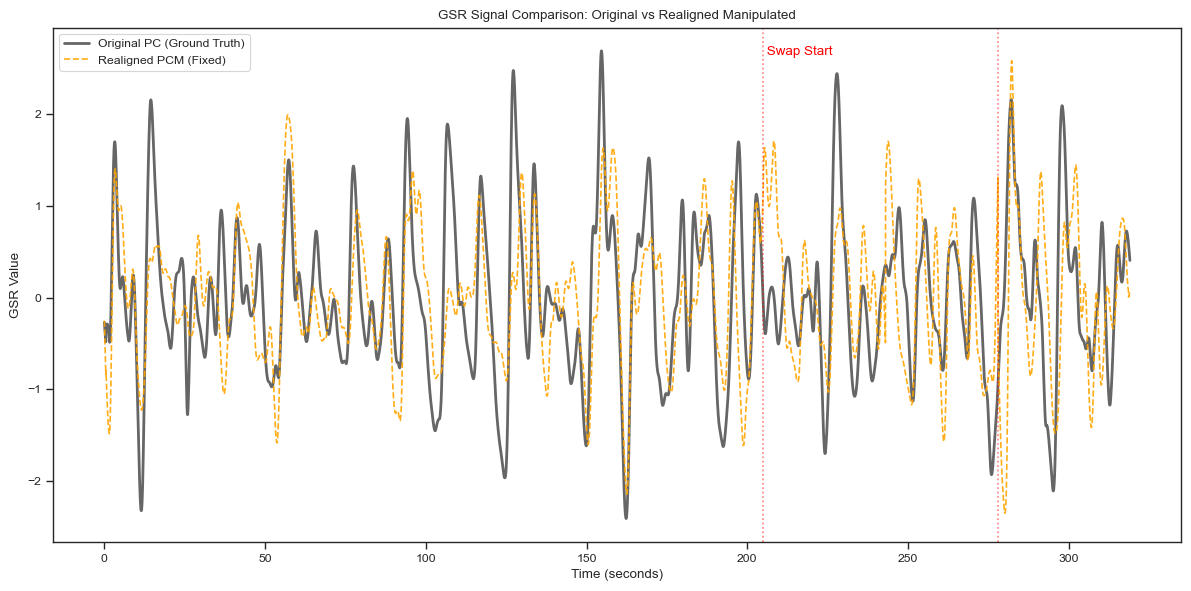

Correlation after realignment: 0.5372


In [40]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ==========================================
# 1. SETUP
# ==========================================
FS = 20  # Sampling rate in Hz

# Assume you have your dataframes loaded as tc_df and tc_df_manipulated
# For the sake of this script, I assign them to variables
original_signal = tc_df['Smooth_GSR'].values
manipulated_signal = tc_df_manipulated['Smooth_GSR'].values

# ==========================================
# 2. DEFINE CUT POINTS (Based on PCM)
# ==========================================
# In the PCM (Manipulated) movie:
# - Everything is normal until 205s.
# - Segment 3 is 205s to 240s (Length: 35s) -> This corresponds to PC Seg 4
# - Segment 4 is 240s to 278s (Length: 38s) -> This corresponds to PC Seg 3
# - Everything is normal after 278s.

t_swap_start = 205
t_mid        = 240
t_swap_end   = 278

# Convert seconds to Indices
idx_start = int(t_swap_start * FS)
idx_mid   = int(t_mid * FS)
idx_end   = int(t_swap_end * FS)

# ==========================================
# 3. REALIGNMENT (SWAP LOGIC)
# ==========================================
# 1. The part before the swap (0 -> 205s)
part_pre = manipulated_signal[:idx_start]

# 2. The part strictly AFTER the swap (278s -> End)
part_post = manipulated_signal[idx_end:]

# 3. The swapped middle chunks
# In PCM, we have [Short_Seg (35s)] then [Long_Seg (38s)]
# We want to flip them to get [Long_Seg (38s)] then [Short_Seg (35s)]
chunk_early_pcm = manipulated_signal[idx_start:idx_mid] # The 35s clip
chunk_late_pcm  = manipulated_signal[idx_mid:idx_end]   # The 38s clip

# Reconstruct: Pre + Late_PCM + Early_PCM + Post
realigned_signal = np.concatenate([
    part_pre, 
    chunk_late_pcm,  # Put the later chunk first
    chunk_early_pcm, # Put the earlier chunk second
    part_post
])

# ==========================================
# 4. VERIFICATION & PLOTTING
# ==========================================

# Check length consistency
print(f"Original Length:   {len(original_signal)}")
print(f"Manipulated Len:   {len(manipulated_signal)}")
print(f"Realigned Length:  {len(realigned_signal)}")

# Create Time Axis
time_axis = np.arange(len(realigned_signal)) / FS

plt.figure(figsize=(12, 6))

# Plot Original PC
plt.plot(time_axis, original_signal, label='Original PC (Ground Truth)', color='black', alpha=0.6, linewidth=2)

# Plot Realigned PCM
plt.plot(time_axis, realigned_signal, label='Realigned PCM (Fixed)', color='orange', linestyle='--', alpha=0.9)

# Highlight the swap area
plt.axvline(t_swap_start, color='red', linestyle=':', alpha=0.5)
plt.axvline(t_swap_end, color='red', linestyle=':', alpha=0.5)
plt.text(t_swap_start, plt.ylim()[1]*0.9, " Swap Start", color='red')

plt.title("GSR Signal Comparison: Original vs Realigned Manipulated")
plt.xlabel("Time (seconds)")
plt.ylabel("GSR Value")
plt.legend()
plt.tight_layout()
plt.show()

# ==========================================
# 5. CALC CORRELATION
# ==========================================
# Simple correlation check to see if they match now
# (Handling slight length mismatch if any exists by truncating to min length)
min_len = min(len(original_signal), len(realigned_signal))
corr = np.corrcoef(original_signal[:min_len], realigned_signal[:min_len])[0,1]
print(f"Correlation after realignment: {corr:.4f}")